# Defining PBO from out-of-sample ranks

Each symmetric split selects the trial with the largest in-sample performance:

$$
n_c^\star=\arg\max_{1\leq n\leq N}R_{c,n}^{\mathrm{IS}}.
$$

Here, $c$ identifies a symmetric split, $R_{c,n}^{\mathrm{IS}}$ is the in-sample performance of trial $n$, $N$ is the number of trials, and $n_c^\star$ is the trial selected within split $c$.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
from itertools import combinations
import math
import sys
import time
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
from RiskLabAI.backtest.probability_of_backtest_overfitting import probability_of_backtest_overfitting
from RiskLabAI.backtest.validation import adaptive_probability_of_backtest_overfitting, bagged_probability_of_backtest_overfitting
DATA_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31'
DATA_DIR = ROOT / 'data' / 'public' / 'fred'
DATA_PATH = ensure_dataset(ROOT, 'fred_sp500')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
raw = pd.read_csv(DATA_PATH)
raw['observation_date'] = pd.to_datetime(raw['observation_date'])
prices = raw.set_index('observation_date')['SP500'].dropna().astype(float).sort_index()
log_returns = np.log(prices).diff()
fast_windows = [3, 5, 10, 20]
slow_windows = [30, 60, 120, 240]
performance_columns = {}
catalog_rows = []
for fast_window in fast_windows:
    for slow_window in slow_windows:
        fast_average = prices.ewm(span=fast_window, adjust=False, min_periods=fast_window).mean()
        slow_average = prices.ewm(span=slow_window, adjust=False, min_periods=slow_window).mean()
        trend_position = np.sign(fast_average - slow_average).replace(0, np.nan).ffill().shift(1)
        for orientation, multiplier in [('Trend', 1.0), ('Reversal', -1.0)]:
            name = f'{orientation} {fast_window}/{slow_window}'
            performance_columns[name] = multiplier * trend_position * log_returns
            catalog_rows.append({'Trial': len(catalog_rows) + 1, 'Rule': orientation, 'Fast span': fast_window, 'Slow span': slow_window, 'Name': name})
performances = pd.DataFrame(performance_columns).dropna()
strategy_catalog = pd.DataFrame(catalog_rows)
FIGURES = ROOT / 'outputs' / 'figures' / '19_backtest_overfitting'
TABLES = ROOT / 'outputs' / 'tables' / '19_backtest_overfitting'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def score_vector(matrix):
    values = np.asarray(matrix, dtype=float)
    deviations = values.std(axis=0)
    means = values.mean(axis=0)
    return np.divide(means, deviations, out=np.zeros_like(means), where=deviations > 0)

def cscv_records(matrix, n_partitions, names=None):
    values = np.asarray(matrix, dtype=float)
    labels = list(names) if names is not None else [f'Trial {index + 1}' for index in range(values.shape[1])]
    groups = np.array_split(np.arange(values.shape[0]), n_partitions)
    all_groups = list(range(n_partitions))
    rows = []
    for combination_number, train_groups in enumerate(combinations(all_groups, n_partitions // 2), start=1):
        test_groups = tuple((group for group in all_groups if group not in train_groups))
        train_indices = np.concatenate([groups[group] for group in train_groups])
        test_indices = np.concatenate([groups[group] for group in test_groups])
        train_scores = score_vector(values[train_indices])
        test_scores = score_vector(values[test_indices])
        selected = int(np.argmax(train_scores))
        ranks = np.argsort(np.argsort(test_scores)) + 1
        selected_rank = int(ranks[selected])
        relative_rank = selected_rank / (values.shape[1] + 1)
        logit = float(np.log(relative_rank / (1.0 - relative_rank)))
        rows.append({'Combination': combination_number, 'Training groups': ', '.join((str(group + 1) for group in train_groups)), 'Testing groups': ', '.join((str(group + 1) for group in test_groups)), 'Training observations': len(train_indices), 'Testing observations': len(test_indices), 'Selected trial': selected + 1, 'Selected name': labels[selected], 'In-sample score': train_scores[selected], 'Out-of-sample score': test_scores[selected], 'Out-of-sample rank': selected_rank, 'Relative rank': relative_rank, 'Logit': logit, 'Overfit': int(logit <= 0.0)})
    return pd.DataFrame(rows)

def manual_pbo(matrix, n_partitions):
    records = cscv_records(matrix, n_partitions)
    return (float(records['Overfit'].mean()), records['Logit'].to_numpy())
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Transforming relative rank into a logit

The selected trial's out-of-sample rank is placed inside the unit interval and then mapped to log odds:

$$
\overline\omega_c=\frac{r_{c,n_c^\star}^{\mathrm{OOS}}}{N+1},
\qquad
\lambda_c=\log\!\left(\frac{\overline\omega_c}{1-\overline\omega_c}\right).
$$

Here, $r_{c,n_c^\star}^{\mathrm{OOS}}$ is the ascending out-of-sample rank of the trial selected in-sample, $N+1$ keeps the relative rank strictly between zero and one, $\overline\omega_c$ is the relative rank, and $\lambda_c$ is its logit. A nonpositive logit places the selected trial in the lower half of the out-of-sample ranking.

,Quantity,Value
0,Observations,2090
1,Trials,32
2,Time groups,8
3,Symmetric combinations,70
4,Released PBO,0.471429
5,Explicit PBO,0.471429
6,Mean logit,-0.111416
7,Median logit,0.060625
8,Out-of-sample loss share,0.471429


,Quantile,Logit,Relative rank
0,0,-3.465736,0.030303
1,0.05,-3.465736,0.030303
2,0.25,-0.943849,0.280303
3,0.50,0.060625,0.515152
4,0.75,0.980829,0.727273
5,0.95,1.981001,0.878788
6,1,3.465736,0.969697


,Combination,Selected name,In-sample score,Out-of-sample score,Out-of-sample rank,Relative rank,Logit,Overfit
0,1,Trend 10/120,0.039625,0.002413,18,0.545455,0.182322,0
1,2,Trend 5/30,0.025458,0.034319,20,0.606061,0.430783,0
2,3,Trend 3/30,0.032784,0.011999,18,0.545455,0.182322,0
3,4,Trend 20/60,0.041934,0.007881,25,0.757576,1.139434,0
4,5,Trend 3/30,0.038372,0.003675,17,0.515152,0.060625,0
5,6,Trend 20/240,0.016513,-0.011249,14,0.424242,-0.305382,1
6,7,Trend 20/240,0.035868,-0.020022,11,0.333333,-0.693147,1
7,8,Trend 20/240,0.070642,-0.039381,1,0.030303,-3.465736,1
8,9,Trend 10/120,0.037896,0.012517,24,0.727273,0.980829,0
9,10,Reversal 20/120,0.040287,-0.038932,13,0.393939,-0.430783,1


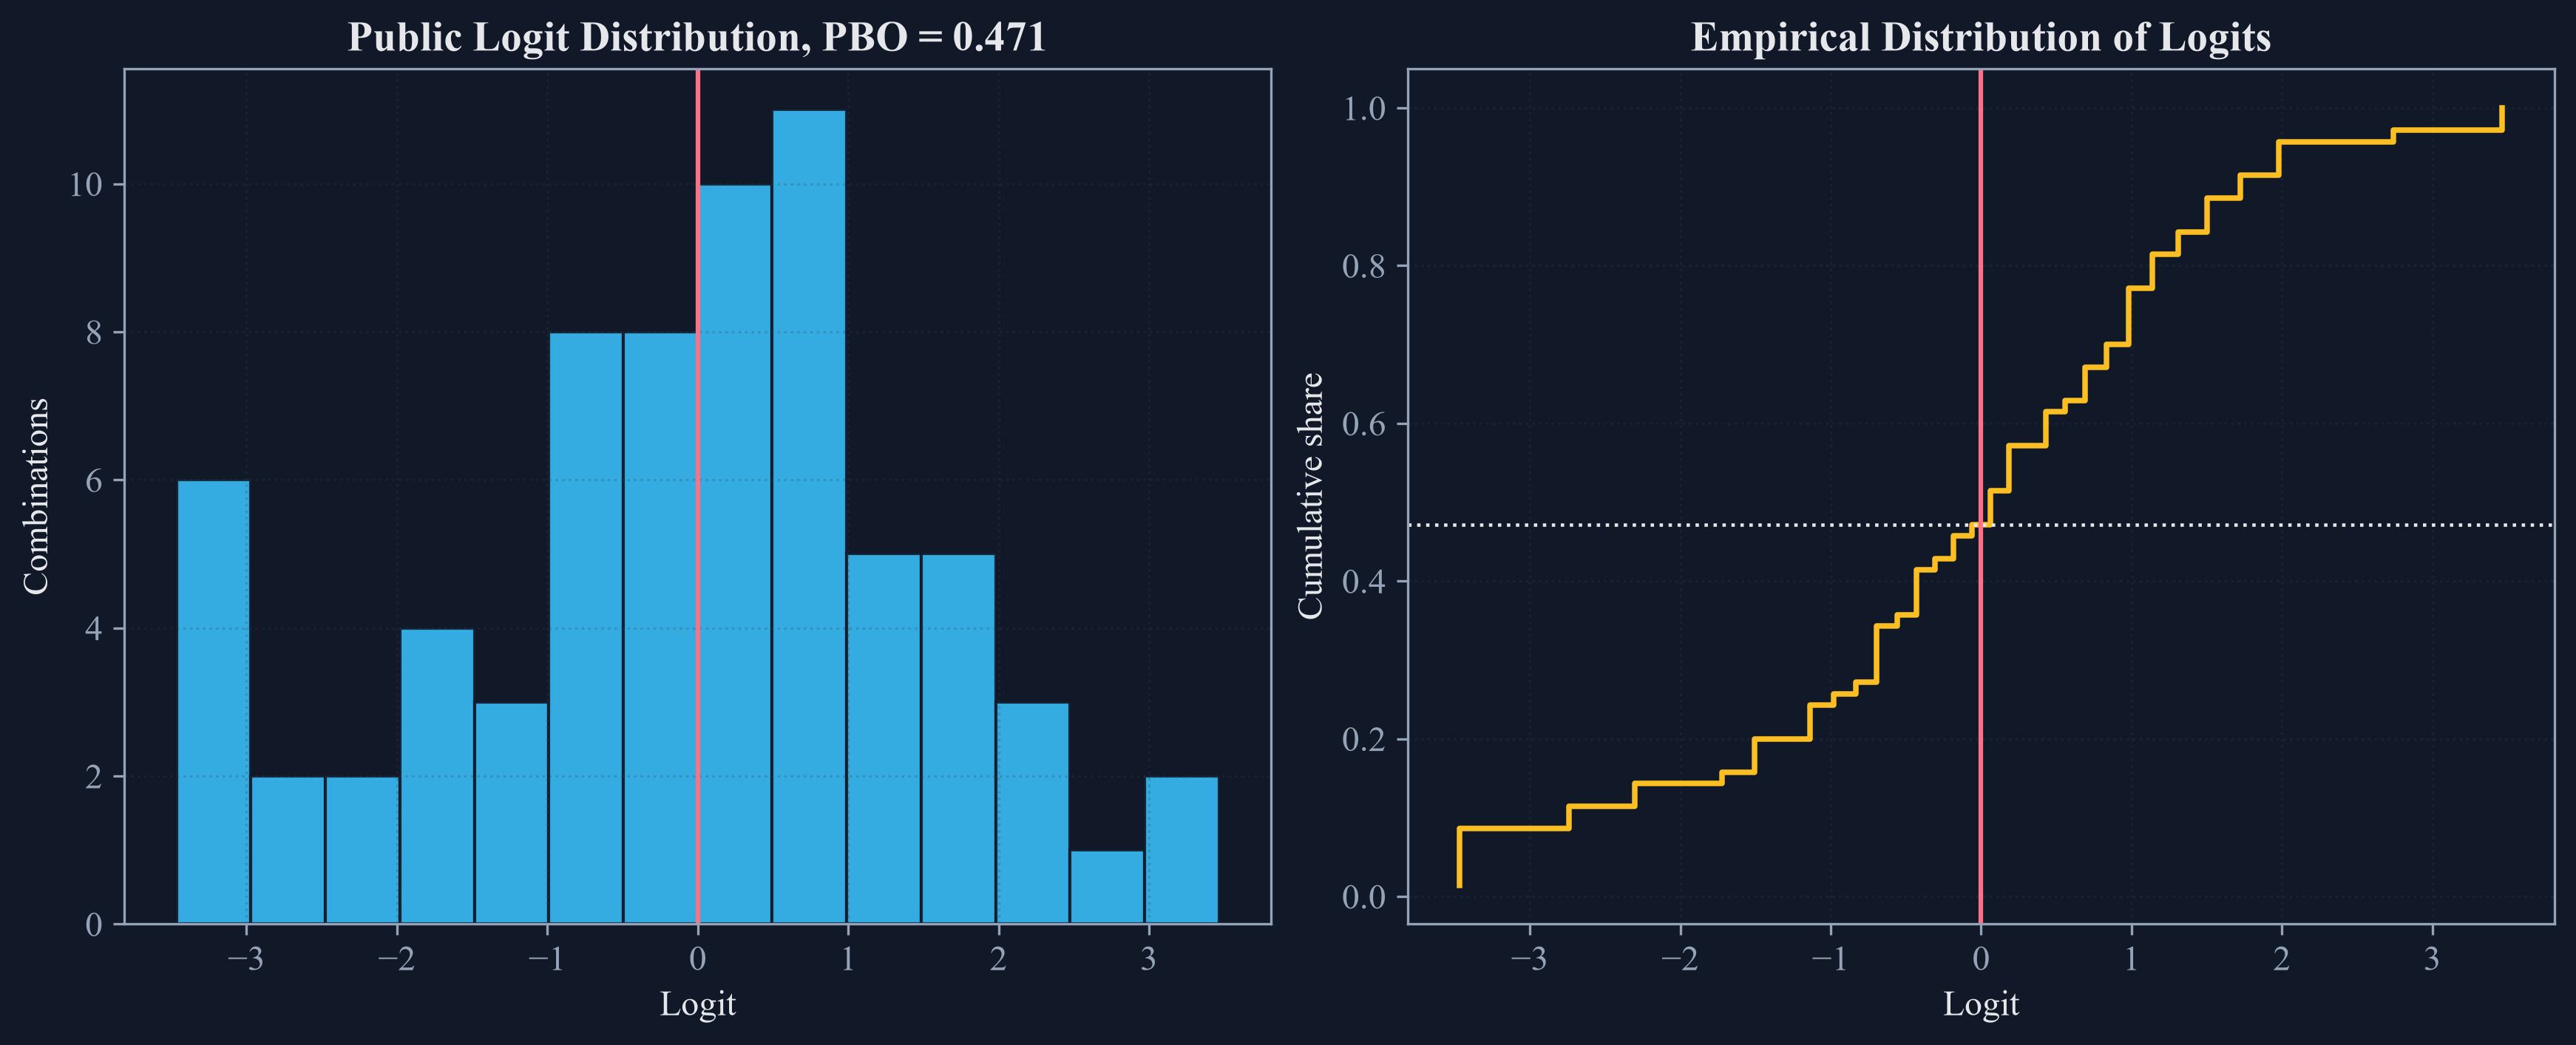

In [2]:
n_partitions = 8
public_records = cscv_records(performances.to_numpy(), n_partitions, performances.columns)
released_pbo, released_logits = probability_of_backtest_overfitting(performances.to_numpy(), n_partitions=n_partitions, n_jobs=1)
manual_value = public_records["Overfit"].mean()
public_summary = pd.DataFrame({
    "Quantity": ["Observations", "Trials", "Time groups", "Symmetric combinations", "Released PBO", "Explicit PBO", "Mean logit", "Median logit", "Out-of-sample loss share"],
    "Value": [len(performances), performances.shape[1], n_partitions, len(public_records), released_pbo, manual_value, public_records["Logit"].mean(), public_records["Logit"].median(), (public_records["Out-of-sample score"] < 0).mean()],
})
quantile_levels = [0.0, 0.05, 0.25, 0.5, 0.75, 0.95, 1.0]
logit_quantiles = pd.DataFrame({"Quantile": quantile_levels, "Logit": public_records["Logit"].quantile(quantile_levels).to_numpy(), "Relative rank": public_records["Relative rank"].quantile(quantile_levels).to_numpy()})
split_examples = public_records[["Combination", "Selected name", "In-sample score", "Out-of-sample score", "Out-of-sample rank", "Relative rank", "Logit", "Overfit"]].head(14)
save_table(public_summary, "public_pbo_summary", "PBO summary for the public strategy family.", "tab:chapter17-public-pbo", fit=False)
save_table(logit_quantiles, "public_logit_quantiles", "Quantiles of public relative ranks and logits.", "tab:chapter17-logit-quantiles", fit=False)
save_table(split_examples, "public_split_examples", "The first fourteen selected-trial outcomes.", "tab:chapter17-split-examples")
display(public_summary)
display(logit_quantiles)
display(split_examples)

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), constrained_layout=True)
axes[0].hist(public_records["Logit"], bins=14, color=palette["cyan"], edgecolor=palette["background"], alpha=0.9)
axes[0].axvline(0, color=palette["rose"], linewidth=1.5)
axes[0].set_title(f"Public Logit Distribution, PBO = {released_pbo:.3f}")
axes[0].set_xlabel("Logit")
axes[0].set_ylabel("Combinations")
axes[0].grid(alpha=0.25)
ordered_logits = np.sort(public_records["Logit"].to_numpy())
cumulative = np.arange(1, len(ordered_logits) + 1) / len(ordered_logits)
axes[1].step(ordered_logits, cumulative, where="post", color=palette["amber"], linewidth=1.8)
axes[1].axvline(0, color=palette["rose"], linewidth=1.5)
axes[1].axhline(released_pbo, color=palette["text"], linestyle=":", linewidth=1.1)
axes[1].set_title("Empirical Distribution of Logits")
axes[1].set_xlabel("Logit")
axes[1].set_ylabel("Cumulative share")
axes[1].grid(alpha=0.25)
figure.savefig(FIGURES / "public_logit_distribution.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_logit_distribution.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_logit_distribution.png")))
plt.close(figure)

The empirical probability of backtest overfitting is the share of nonpositive logits:

$$
\widehat\phi
=\frac{1}{C_S}\sum_{c=1}^{C_S}\one\{\lambda_c\leq0\}.
$$

Here, $\widehat\phi$ is the PBO estimate, $C_S$ is the number of symmetric combinations, $\lambda_c$ is the logit for combination $c$, and $\one\{\lambda_c\leq0\}$ equals one when the selected trial ranks in the lower out-of-sample half and zero otherwise.

## Performance Degradation

A straight-line summary relates the selected trial's out-of-sample score to its in-sample score:

$$
R_c^{\mathrm{OOS}}=\alpha+\beta R_c^{\mathrm{IS}}+\varepsilon_c.
$$

Here, $R_c^{\mathrm{IS}}$ and $R_c^{\mathrm{OOS}}$ are the selected trial's two scores in split $c$, $\alpha$ is the fitted intercept, $\beta$ is the fitted slope, and $\varepsilon_c$ is the part not explained by the straight line. This descriptive slope does not establish causation.

,Selected trial,Selected name,Selections,Mean out-of-sample score,Overfit share,Selection share
2,9,Trend 5/30,15,0.027465,0,0.214286
8,27,Trend 20/60,12,0.004999,0.333333,0.171429
0,1,Trend 3/30,11,0.008277,0.181818,0.157143
10,31,Trend 20/240,8,-0.024273,1,0.114286
6,21,Trend 10/120,5,0.002005,0.400000,0.071429
4,15,Trend 5/240,4,-0.023301,1,0.057143
9,30,Reversal 20/120,4,-0.046633,1,0.057143
3,13,Trend 5/120,3,0.005180,0.333333,0.042857
7,23,Trend 10/240,3,-0.018974,1,0.042857
11,32,Reversal 20/240,3,-0.059724,1,0.042857


,Quantity,Value
0,Intercept,0.035206
1,Slope,-0.962999
2,Score correlation,-0.478701
3,Out-of-sample loss share,0.471429
4,Distinct selected trials,12


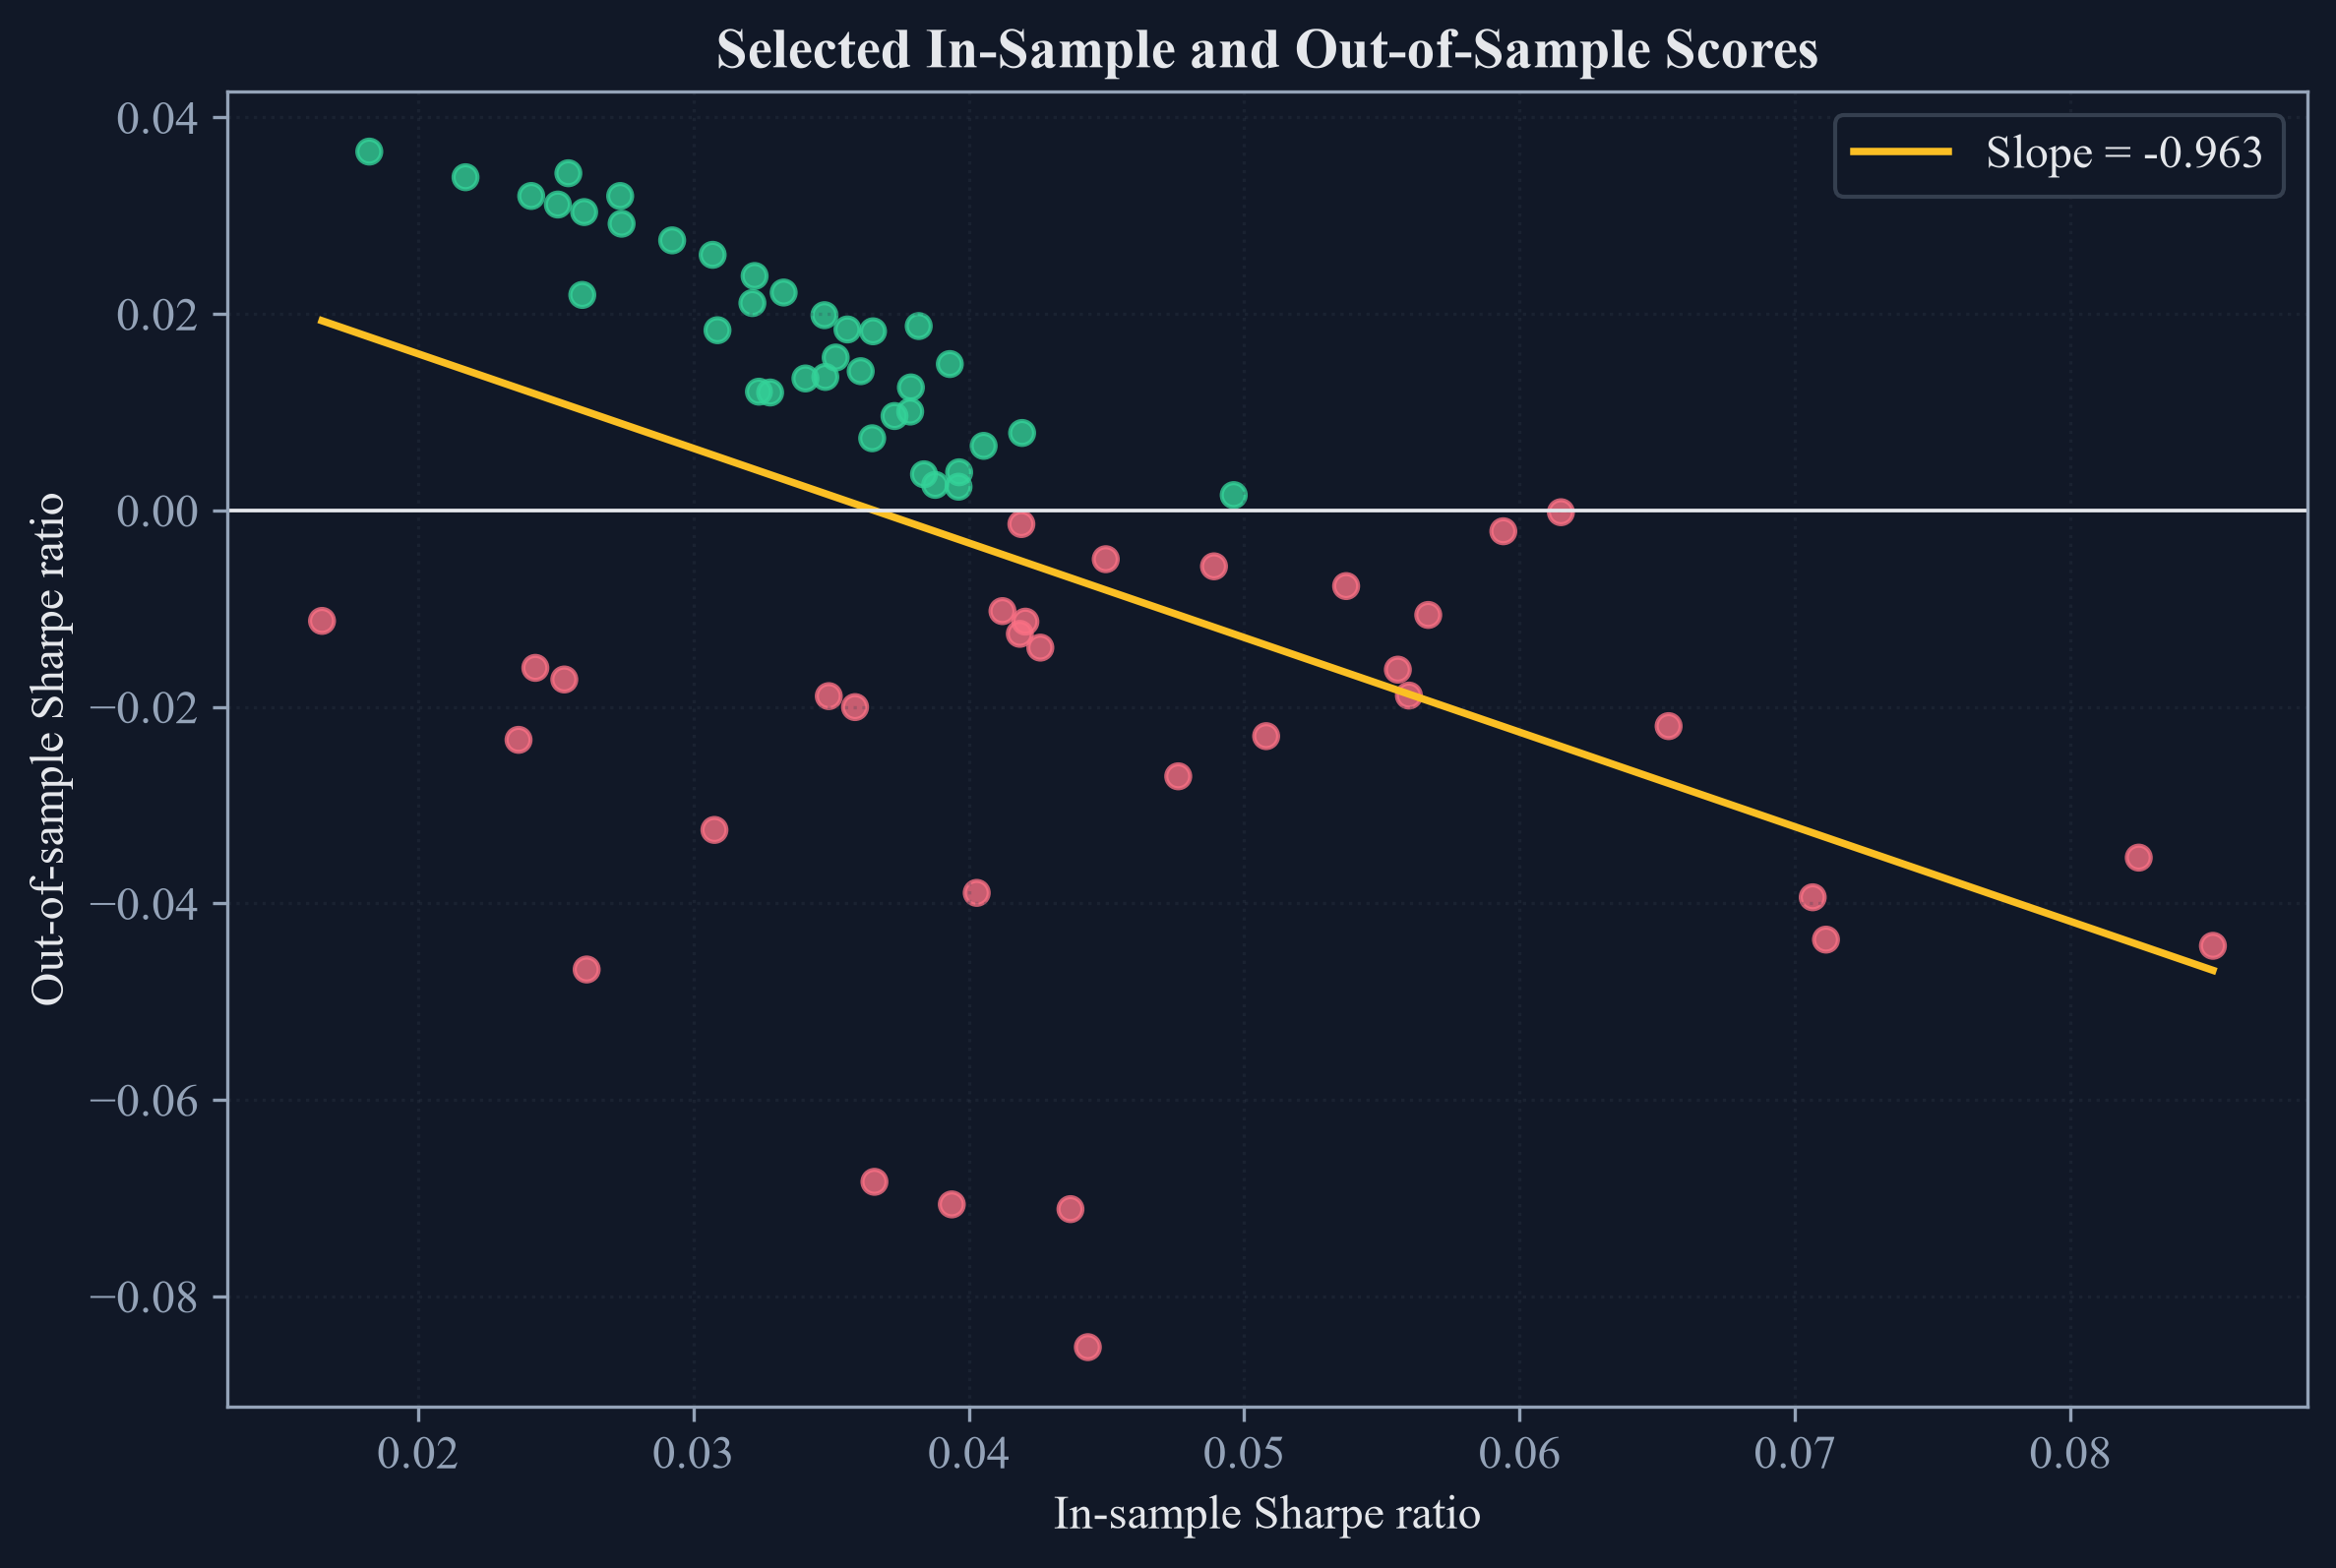

In [3]:
slope, intercept = np.polyfit(public_records["In-sample score"], public_records["Out-of-sample score"], 1)
correlation = public_records[["In-sample score", "Out-of-sample score"]].corr().iloc[0, 1]
selection_frequency = public_records.groupby(["Selected trial", "Selected name"], as_index=False).agg(Selections=("Combination", "size"), Mean_out_of_sample_score=("Out-of-sample score", "mean"), Overfit_share=("Overfit", "mean")).rename(columns={"Mean_out_of_sample_score": "Mean out-of-sample score", "Overfit_share": "Overfit share"}).sort_values(["Selections", "Selected trial"], ascending=[False, True])
selection_frequency["Selection share"] = selection_frequency["Selections"] / len(public_records)
degradation_summary = pd.DataFrame({"Quantity": ["Intercept", "Slope", "Score correlation", "Out-of-sample loss share", "Distinct selected trials"], "Value": [intercept, slope, correlation, (public_records["Out-of-sample score"] < 0).mean(), len(selection_frequency)]})
save_table(selection_frequency, "public_selection_frequency", "Selection frequencies across public symmetric splits.", "tab:chapter17-selection-frequency")
save_table(degradation_summary, "performance_degradation_summary", "Descriptive relation between selected in-sample and out-of-sample scores.", "tab:chapter17-degradation-summary", fit=False)
display(selection_frequency)
display(degradation_summary)

x_values = np.linspace(public_records["In-sample score"].min(), public_records["In-sample score"].max(), 100)
figure, axis = plt.subplots(figsize=(7.8, 5.2), constrained_layout=True)
colors = np.where(public_records["Overfit"].to_numpy() == 1, palette["rose"], palette["green"])
axis.scatter(public_records["In-sample score"], public_records["Out-of-sample score"], c=colors, alpha=0.78, s=34)
axis.plot(x_values, intercept + slope * x_values, color=palette["amber"], linewidth=1.8, label=f"Slope = {slope:.3f}")
axis.axhline(0, color=palette["text"], linewidth=0.9)
axis.set_title("Selected In-Sample and Out-of-Sample Scores")
axis.set_xlabel("In-sample Sharpe ratio")
axis.set_ylabel("Out-of-sample Sharpe ratio")
axis.legend()
axis.grid(alpha=0.25)
figure.savefig(FIGURES / "public_performance_degradation.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_performance_degradation.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_performance_degradation.png")))
plt.close(figure)

## Preliminary Null Experiments

If the overfit indicators were independent Bernoulli observations, a useful scale for the sampling error of their mean would be:

$$
\operatorname{SE}(\widehat\phi)\approx\sqrt{\frac{\widehat\phi(1-\widehat\phi)}{C_S}}.
$$

Here, $\operatorname{SE}(\widehat\phi)$ is the approximate standard error, $\widehat\phi$ is the observed PBO, and $C_S$ is the number of logits. The symmetric combinations share observations, so this expression is a scale calculation rather than an exact independent-sample uncertainty statement.

,Experiment,Observations,Trials,Time groups,Logits,PBO,Approximate standard error
0,"Seed 1, standard normal",1000,50,10,252,0.654762,0.02995
1,"Seed 42, small common drift",1000,50,16,12870,0.544678,0.00439


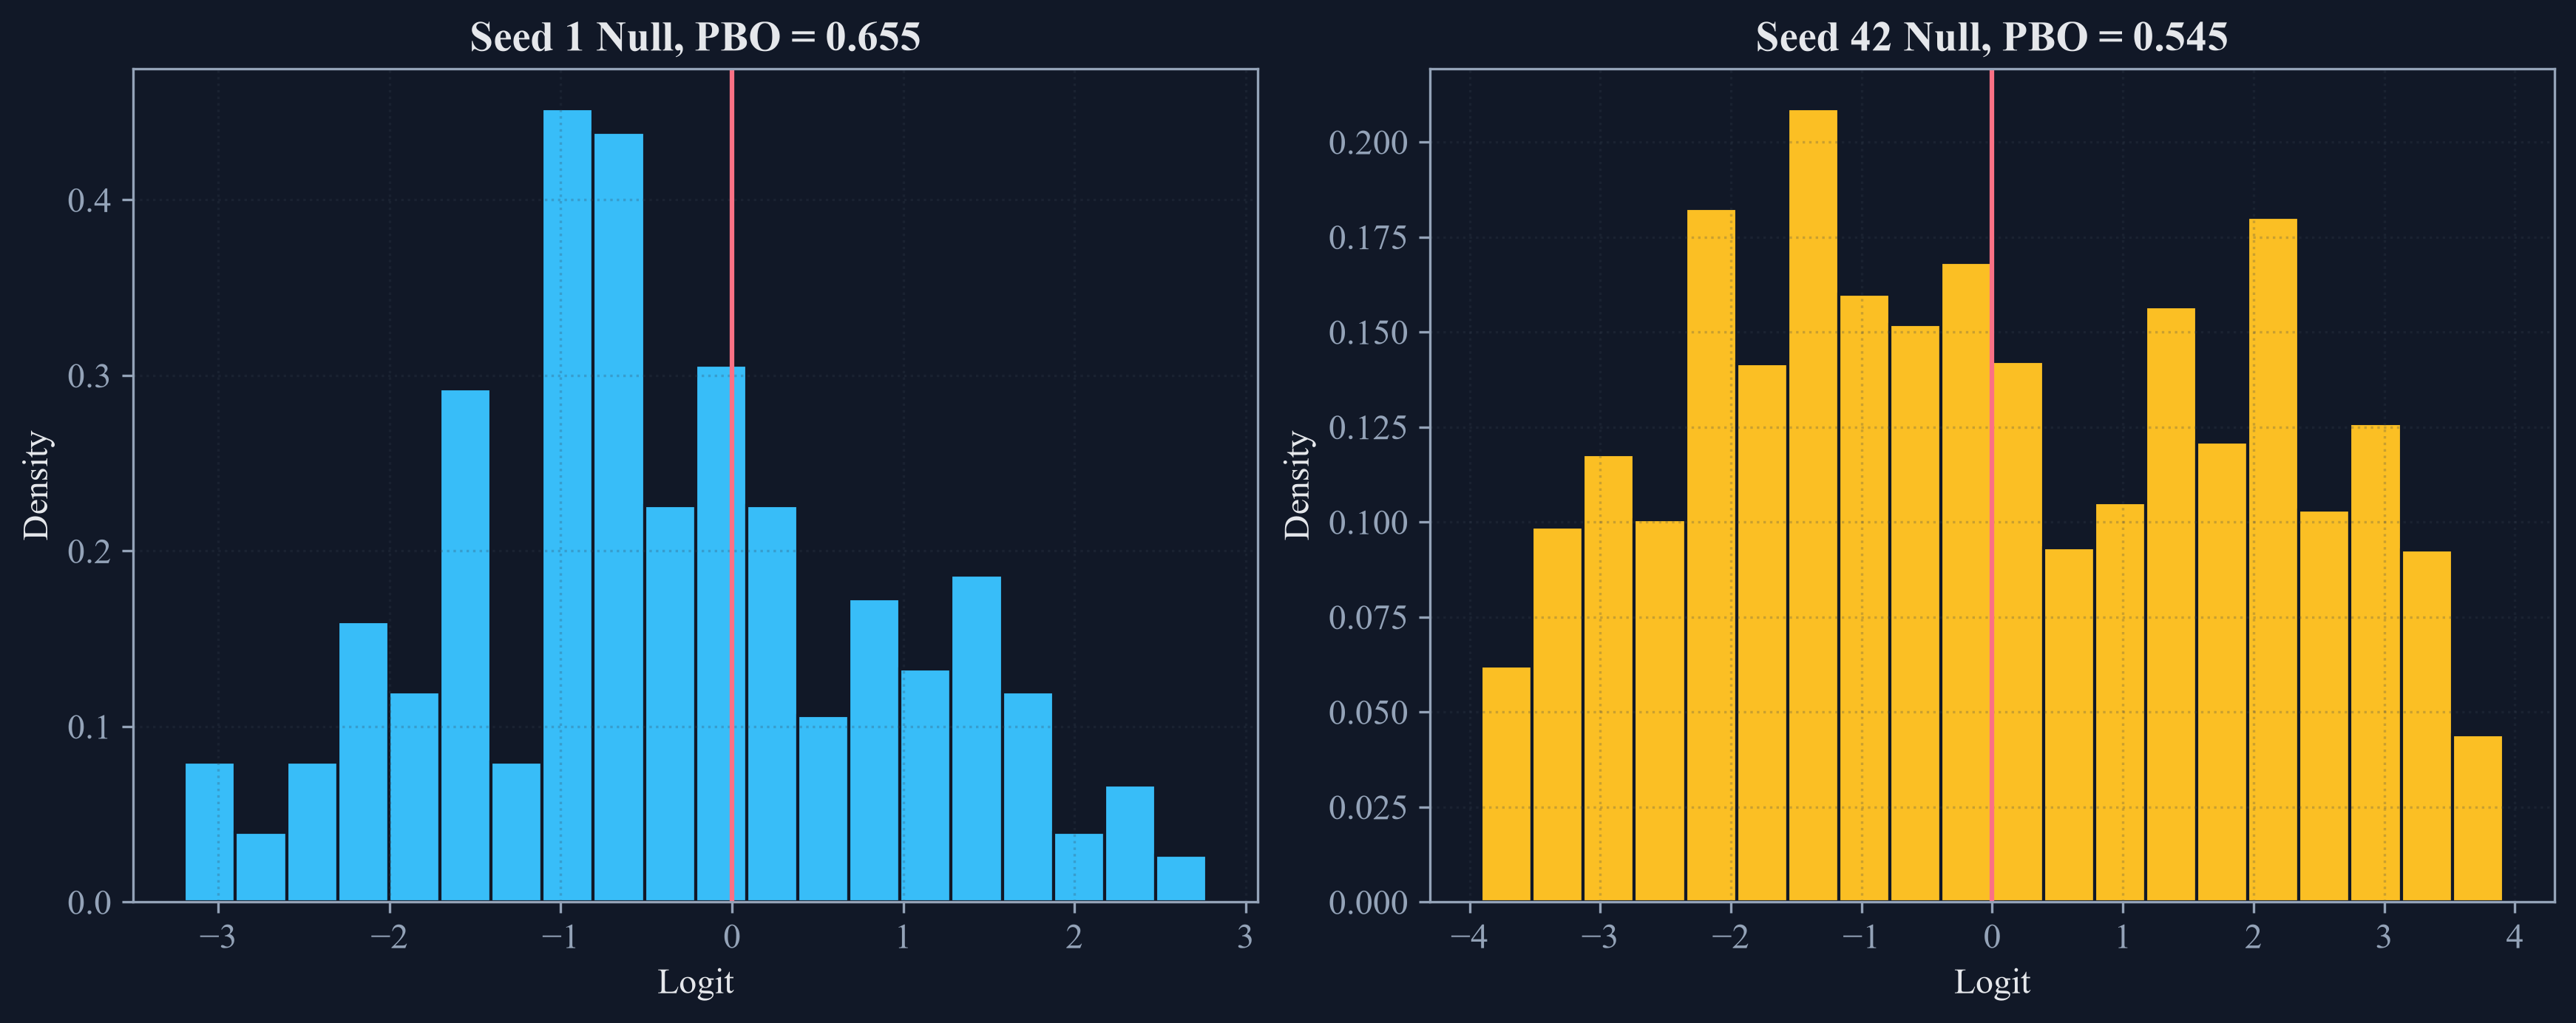

In [4]:
first_rng = np.random.default_rng(1)
first_null = first_rng.normal(0, 1, (1000, 50))
first_pbo, first_logits = probability_of_backtest_overfitting(first_null, n_partitions=10, n_jobs=1)
second_rng = np.random.RandomState(42)
second_null = second_rng.normal(loc=0.0001, scale=0.01, size=(1000, 50))
second_pbo, second_logits = probability_of_backtest_overfitting(second_null, n_partitions=16, n_jobs=1)
preliminary_reproduction = pd.DataFrame({
    "Experiment": ["Seed 1, standard normal", "Seed 42, small common drift"],
    "Observations": [1000, 1000],
    "Trials": [50, 50],
    "Time groups": [10, 16],
    "Logits": [len(first_logits), len(second_logits)],
    "PBO": [first_pbo, second_pbo],
    "Approximate standard error": [np.sqrt(first_pbo * (1 - first_pbo) / len(first_logits)), np.sqrt(second_pbo * (1 - second_pbo) / len(second_logits))],
})
save_table(preliminary_reproduction, "preliminary_null_reproduction", "Reproduction of the two preliminary no-skill PBO experiments.", "tab:chapter17-null-reproduction")
display(preliminary_reproduction)

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), constrained_layout=True)
axes[0].hist(first_logits, bins=20, density=True, color=palette["cyan"], edgecolor=palette["background"])
axes[0].axvline(0, color=palette["rose"], linewidth=1.5)
axes[0].set_title(f"Seed 1 Null, PBO = {first_pbo:.3f}")
axes[1].hist(second_logits, bins=20, density=True, color=palette["amber"], edgecolor=palette["background"])
axes[1].axvline(0, color=palette["rose"], linewidth=1.5)
axes[1].set_title(f"Seed 42 Null, PBO = {second_pbo:.3f}")
for axis in axes:
    axis.set_xlabel("Logit")
    axis.set_ylabel("Density")
    axis.grid(alpha=0.25)
figure.savefig(FIGURES / "preliminary_null_logits.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "preliminary_null_logits.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "preliminary_null_logits.png")))
plt.close(figure)

## Tests

In [5]:
assert len(public_records) == 70
assert len(released_logits) == 70
assert np.isclose(released_pbo, manual_value)
assert np.allclose(released_logits, public_records['Logit'].to_numpy())
assert public_records['Relative rank'].between(0, 1, inclusive='neither').all()
assert public_records['Overfit'].isin([0, 1]).all()
assert np.isclose(selection_frequency['Selection share'].sum(), 1)
assert selection_frequency['Selections'].sum() == 70
assert round(first_pbo, 3) == 0.655
assert round(second_pbo, 4) == 0.5447
assert len(first_logits) == math.comb(10, 5) == 252
assert len(second_logits) == math.comb(16, 8) == 12870
assert (FIGURES / 'public_logit_distribution.pdf').is_file()
assert (FIGURES / 'public_performance_degradation.pdf').is_file()
assert (FIGURES / 'preliminary_null_logits.pdf').is_file()
assert (TABLES / 'public_pbo_summary.tex').is_file()
assert (TABLES / 'public_logit_quantiles.tex').is_file()
assert (TABLES / 'public_split_examples.tex').is_file()
assert (TABLES / 'public_selection_frequency.tex').is_file()
assert (TABLES / 'performance_degradation_summary.tex').is_file()
assert (TABLES / 'preliminary_null_reproduction.tex').is_file()
